# Forest Sentinel ML experiments

This notebook orchestrates the event-level RemoteCLIP experiments. Data access, caching, splitting, model fitting, and report generation are implemented in reusable Python modules under `ml_tests`.

## 1. Environment and configuration

This section locates the repository, loads the versioned JSON configuration, and creates a new run directory. Database mutations and expensive model inference are disabled by default.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "Scripts" / "ResearchScripts" / "ml_tests").exists()
)
RESEARCH_SCRIPTS_ROOT = PROJECT_ROOT / "Scripts" / "ResearchScripts"
if str(RESEARCH_SCRIPTS_ROOT) not in sys.path:
    sys.path.insert(0, str(RESEARCH_SCRIPTS_ROOT))

from ml_tests.config import load_config
from ml_tests.pipeline import ForestMLPipeline

CONFIG_PATH = PROJECT_ROOT / "Scripts" / "ResearchScripts" / "ml_tests" / "configs" / "forest_ml_v1.json"
PROFILE = "quick"
APPLY_EVENT_BACKFILL = False
RUN_EMBEDDINGS = True
RUN_BASELINE = True
REUSE_SAVED_BASELINE = True

config = load_config(CONFIG_PATH, profile=PROFILE)
pipeline = ForestMLPipeline(config)
{"profile": PROFILE, "run_dir": str(pipeline.run_dir), "database": str(pipeline.database_path)}

{'profile': 'quick',
 'run_dir': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchScripts\\Outputs\\ml_experiments\\20261019_015904',
 'database': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchTool\\Data\\forest\\state.sqlite'}

## 2. Legacy event-link backfill plan

The dry-run identifies Sentinel downloads without event links and assigns only unambiguous cases to the single dominant Hansen event. Existing links are preserved. Applying the plan first creates a SQLite backup and then writes all links in one transaction.

In [2]:
backfill_plan = pipeline.plan_event_backfill()
backfill_plan["counts"]

{'already_linked': 1679, 'missing_dominant_event': 3, 'would_link': 1700}

In [3]:
if APPLY_EVENT_BACKFILL:
    backfill_result = pipeline.apply_event_backfill(backfill_plan)
    backfill_plan = pipeline.plan_event_backfill()
    print(backfill_result["counts"])
else:
    print("Dry-run only. Planned links will be used virtually in the manifest.")

Dry-run only. Planned links will be used virtually in the manifest.


## 3. Event-level dataset manifest

The manifest reads samples, Hansen events, Sentinel downloads, RGB previews, manual validation, and quality reviews directly from the database. Excluded or missing images remain in the manifest with explicit reasons but are not passed to RemoteCLIP.

In [4]:
manifest, dataset_audit = pipeline.build_manifest(backfill_plan=backfill_plan)
dataset_audit

{'rows': 3580,
 'eligible_rows': 2555,
 'excluded_rows': 1025,
 'unique_samples': 287,
 'eligible_samples': 287,
 'unique_events': 362,
 'eligible_events': 362,
 'cohort_counts': {'MANUAL_TOO_OLD': 36,
  'MANUAL_UNCLEAR': 494,
  'MANUAL_VALID': 850,
  'MANUAL_WRONG': 47,
  'NO_MANUAL_WEAK': 1128},
 'sample_counts_by_cohort': {'MANUAL_TOO_OLD': 9,
  'MANUAL_UNCLEAR': 66,
  'MANUAL_VALID': 117,
  'MANUAL_WRONG': 8,
  'NO_MANUAL_WEAK': 87},
 'event_counts_by_cohort': {'MANUAL_TOO_OLD': 9,
  'MANUAL_UNCLEAR': 66,
  'MANUAL_VALID': 118,
  'MANUAL_WRONG': 8,
  'NO_MANUAL_WEAK': 161},
 'class_counts': {'Logging': 819, 'Wildfire': 1736},
 'period_counts': {'EVENT': 459, 'POST': 1045, 'PRE': 1051},
 'event_assignment_counts': {'EXPLICIT': 2012,
  'LEGACY_DOMINANT_BACKFILL': 1568},
 'reason_counts': {'BAD_CLOUD': 494,
  'BAD_QUALITY': 346,
  'SCENE_REVIEW_EXCLUDED': 1000},
 'database_fingerprint': {'path': 'Scripts/ResearchTool/Data/forest/state.sqlite',
  'size': 40390656,
  'mtime_ns': 1792358

## 4. RemoteCLIP embedding cache

Each embedding is stored outside the notebook in a fingerprinted cache namespace. A cache hit avoids model inference; interrupted runs continue from missing entries. Change `RUN_EMBEDDINGS` only after checking the manifest and cache path.

In [5]:
embeddings = {}
embedding_report = {"counts": {}, "status": "skipped"}
if RUN_EMBEDDINGS:
    embeddings, embedding_report = pipeline.compute_embeddings(manifest)
{key: embedding_report.get(key) for key in ("status", "policy", "cache_path", "embedder_fingerprint", "counts")}

Embeddings 1/2211: {'hits': 1}
Embeddings 25/2211: {'hits': 25}
Embeddings 50/2211: {'hits': 50}
Embeddings 75/2211: {'hits': 75}
Embeddings 100/2211: {'hits': 100}
Embeddings 125/2211: {'hits': 125}
Embeddings 150/2211: {'hits': 150}
Embeddings 175/2211: {'hits': 175}
Embeddings 200/2211: {'hits': 200}
Embeddings 225/2211: {'hits': 225}
Embeddings 250/2211: {'hits': 250}
Embeddings 275/2211: {'hits': 275}
Embeddings 300/2211: {'hits': 300}
Embeddings 325/2211: {'hits': 325}
Embeddings 350/2211: {'hits': 350}
Embeddings 375/2211: {'hits': 375}
Embeddings 400/2211: {'hits': 400}
Embeddings 425/2211: {'hits': 425}
Embeddings 450/2211: {'hits': 450}
Embeddings 475/2211: {'hits': 475}
Embeddings 500/2211: {'hits': 500}
Embeddings 525/2211: {'hits': 525}
Embeddings 550/2211: {'hits': 550}
Embeddings 575/2211: {'hits': 575}
Embeddings 600/2211: {'hits': 600}
Embeddings 625/2211: {'hits': 625}
Embeddings 650/2211: {'hits': 650}
Embeddings 675/2211: {'hits': 675}
Embeddings 700/2211: {'hits': 

{'status': None,
 'policy': 'read_write',
 'cache_path': 'C:\\Users\\Hp\\OneDrive\\Рабочий стол\\учёба\\ML\\ML-SbPSTU-2026\\Scripts\\ResearchTool\\Data\\cache\\forest\\ml_embeddings\\c5d4ceab3d2f7ec9',
 'embedder_fingerprint': 'c5d4ceab3d2f7ec9e225bc4b773c22014fde25f38f14f70bf94a280f9001c537',
 'counts': {'hits': 2211}}

## 5. Saved group splits and baseline experiments

The baseline aggregates normalized image embeddings by event and period, reuses identical saved folds across cohort modes, and weights events so that each territory has total weight one. The main test cohort confirms event existence but still uses the WRI class as a weak target.

In [6]:
baseline_result = pipeline.load_previous_baseline() if REUSE_SAVED_BASELINE else None
baseline_summary = {"status": "skipped"}
if baseline_result is not None:
    baseline_summary = {
        "status": "reused",
        "source_run": baseline_result["saved_run_dir"],
        "metric_rows": len(baseline_result["baseline_metrics"]),
        "fold_rows": len(baseline_result["fold_metrics"]),
        "review_rows": len(baseline_result["nomanual_review_queue"]),
    }
elif RUN_BASELINE:
    if not embeddings:
        raise RuntimeError("RUN_BASELINE requires available embeddings.")
    baseline_result = pipeline.run_baseline(manifest, embeddings)
    baseline_summary = {
        "status": "completed",
        "metric_rows": len(baseline_result["baseline_metrics"]),
        "fold_rows": len(baseline_result["fold_metrics"]),
        "review_rows": len(baseline_result["nomanual_review_queue"]),
    }
baseline_summary

{'status': 'reused',
 'source_run': 'Scripts/ResearchScripts/Outputs/ml_experiments/20261019_014718',
 'metric_rows': 30,
 'fold_rows': 150,
 'review_rows': 125}

## 6. Metrics and review candidates

The table reports mean and standard deviation across saved folds. The plots compare feature variants and cohort modes. `MANUAL_VALID` confirms that an event exists, while the Logging/Wildfire target remains the WRI weak label.

Features,Mode,Split,Runs,Accuracy,Balanced accuracy,F1,ROC-AUC
DELTA,MANUAL_ONLY,stratified,5,0.753 +/- 0.097,0.753 +/- 0.105,0.692 +/- 0.124,0.835 +/- 0.113
DELTA,MANUAL_ONLY,stratified_group,5,0.718 +/- 0.059,0.713 +/- 0.082,0.634 +/- 0.110,0.849 +/- 0.094
DELTA,MANUAL_PLUS_WEAK,stratified_group,5,0.668 +/- 0.087,0.681 +/- 0.083,0.627 +/- 0.075,0.727 +/- 0.065
DELTA,WEAK_INTERNAL_DIAGNOSTIC,stratified_group,5,0.837 +/- 0.047,0.498 +/- 0.074,0.909 +/- 0.031,0.562 +/- 0.276
DELTA,WEAK_ONLY_TO_MANUAL,stratified_group,5,0.325 +/- 0.137,0.402 +/- 0.162,0.432 +/- 0.144,0.403 +/- 0.131
POST,MANUAL_ONLY,stratified,5,0.907 +/- 0.050,0.922 +/- 0.039,0.888 +/- 0.056,0.994 +/- 0.007
POST,MANUAL_ONLY,stratified_group,5,0.881 +/- 0.032,0.891 +/- 0.031,0.854 +/- 0.038,0.983 +/- 0.015
POST,MANUAL_PLUS_WEAK,stratified_group,5,0.958 +/- 0.026,0.947 +/- 0.036,0.939 +/- 0.040,0.991 +/- 0.009
POST,WEAK_INTERNAL_DIAGNOSTIC,stratified_group,5,0.840 +/- 0.104,0.821 +/- 0.180,0.900 +/- 0.075,0.852 +/- 0.205
POST,WEAK_ONLY_TO_MANUAL,stratified_group,5,0.864 +/- 0.115,0.858 +/- 0.117,0.822 +/- 0.147,0.919 +/- 0.077


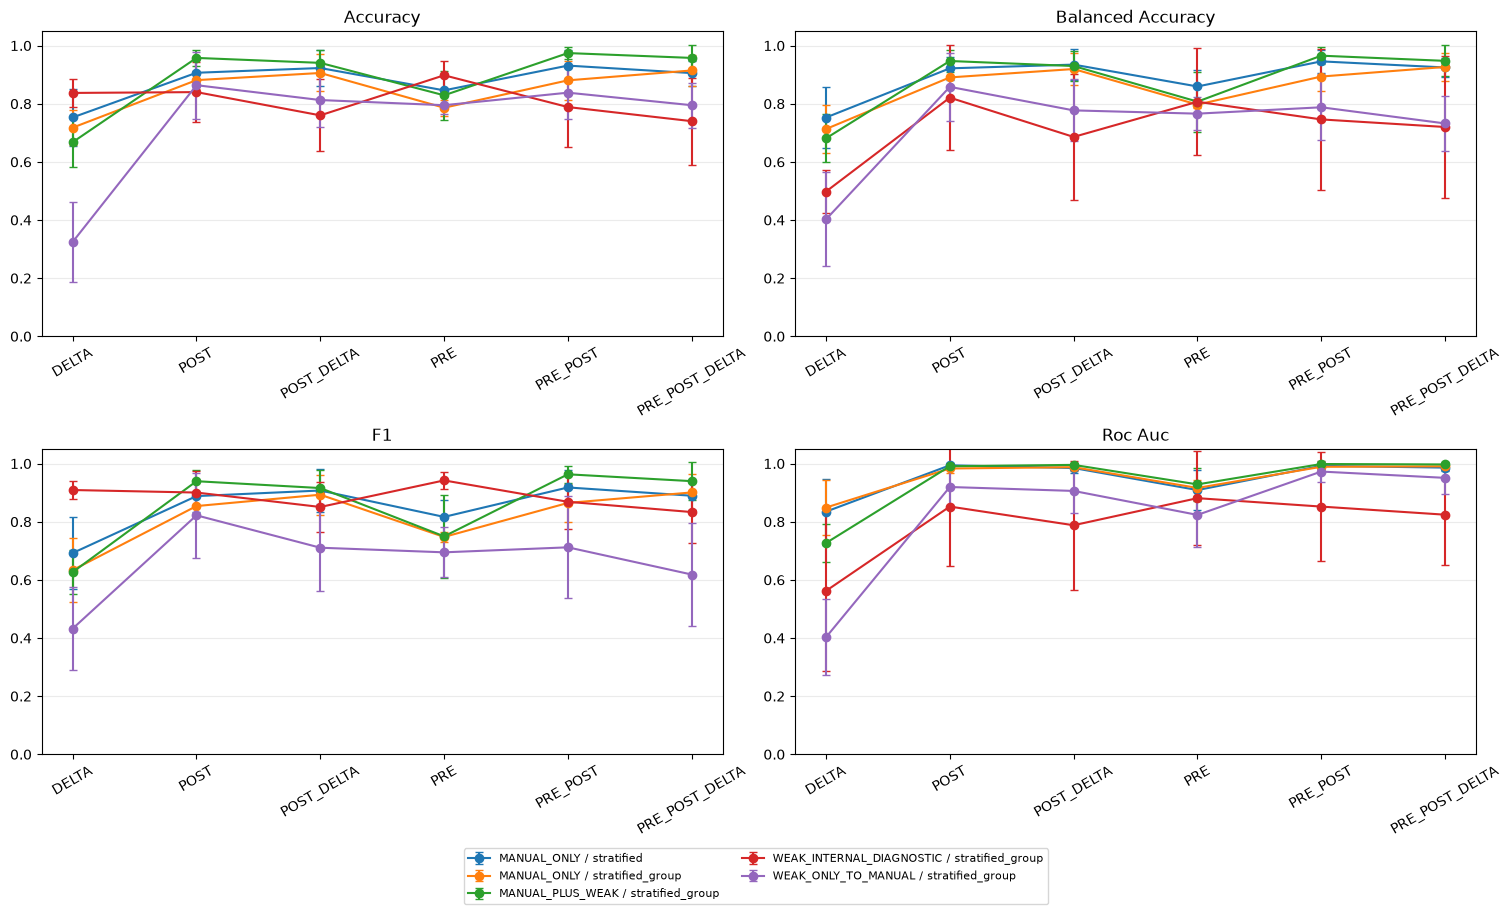

Highest-priority NoManual candidates


sample_id,event_year,weak_label,predicted_class,probability_wildfire,agreement_with_weak_label,review_priority
6940b35ce2dadb561965706f0bfc75f1ee928346,2017,Wildfire,Logging,0.006,False,0.994
ab55a0b673690586016f96dcc8f5aee8affa9fd2,2022,Logging,Wildfire,0.994,False,0.994
faba685ae3339c1ae810df127a16013b3fc84185,2017,Wildfire,Logging,0.011,False,0.989
faba685ae3339c1ae810df127a16013b3fc84185,2018,Wildfire,Logging,0.012,False,0.988
e27a164d7d4a66df04599c4b9cbbeca31db4e502,2016,Logging,Wildfire,0.964,False,0.964
17856b24aae3701d0d06f245f673c52455840ac2,2020,Wildfire,Logging,0.369,False,0.631
8ff59b659e356fa14e08620c0705fa78e951ba18,2017,Logging,Wildfire,0.593,False,0.593
a8cfaa4eaa1f9f5cc69baaf515cb385482ff8322,2016,Wildfire,Logging,0.417,False,0.583
17856b24aae3701d0d06f245f673c52455840ac2,2019,Wildfire,Wildfire,0.556,True,0.444
675b5c455ff651394f4bf1d08a271c03fbf9789a,2022,Wildfire,Wildfire,0.678,True,0.322


In [7]:
from IPython.display import HTML, display
import matplotlib.pyplot as plt
from ml_tests.reporting import baseline_metrics_html, plot_baseline_metrics, review_queue_html

if baseline_result is None:
    print("No compatible saved metrics are available and the baseline was not run.")
else:
    display(HTML(baseline_metrics_html(baseline_result["baseline_metrics"])))
    metrics_figure = plot_baseline_metrics(baseline_result["baseline_metrics"])
    display(metrics_figure)
    plt.close(metrics_figure)
    print("Highest-priority NoManual candidates")
    display(HTML(review_queue_html(baseline_result["nomanual_review_queue"], limit=20)))

## 7. Run summary

All detailed tables, saved splits, review queues, and cache diagnostics are written to the run directory. The notebook keeps only compact summaries in cell outputs.

In [8]:
pipeline.summary

{'status': 'initialized',
 'run_dir': 'Scripts/ResearchScripts/Outputs/ml_experiments/20261019_015904',
 'started_at': '2026-10-18T22:59:04.308580+00:00',
 'profile': 'quick',
 'event_backfill_plan': {'already_linked': 1679,
  'missing_dominant_event': 3,
  'would_link': 1700},
 'updated_at': '2026-10-18T23:00:39.103797+00:00',
 'dataset': {'rows': 3580,
  'eligible_rows': 2555,
  'eligible_samples': 287,
  'eligible_events': 362},
 'embedding_cache': {'hits': 2211},
 'reused_baseline': 'Scripts/ResearchScripts/Outputs/ml_experiments/20261019_014718'}